# GridS and the uniform control

## 1. Load shared code
These are compact implementations of the proposal, not exact reproductions of the paper architecture. Both use 16 tokens per camera and the same bilinear interpolation, coordinate embedding, and downstream head.

In [3]:
from pathlib import Path
import sys, json
import torch, torchvision
project_dir = Path.home() / "t2-project"
sys.path.insert(0, str(project_dir))
from t2.train import train, load_policy
from t2.data import preparation, vocabulary, Demonstrations
manifest, normalization, manifest_hash = preparation(project_dir)
print("Project:", project_dir)

Project: /home/njmcmil/t2-project


## 2. Train GridS
Global visual pooling feeds a network that predicts continuous coordinates. Bilinear sampling blends nearby spatial features and carries gradients back to the coordinate network. Language enters the shared policy head; the original sampler here uses visual features only.

In [4]:
grids_run = train(project_dir, "grids", seed=0, epochs=10)

Run: /home/njmcmil/t2-project/runs/grids_seed0_20261117T212203_540220Z
Epoch 1/10: train=0.97523, validation=1.00841
Epoch 2/10: train=0.81775, validation=0.75035
Epoch 3/10: train=0.69943, validation=0.67840
Epoch 4/10: train=0.61326, validation=0.65483
Epoch 5/10: train=0.56310, validation=0.57855
Epoch 6/10: train=0.52278, validation=0.53999
Epoch 7/10: train=0.47399, validation=0.52471
Epoch 8/10: train=0.45570, validation=0.53350
Epoch 9/10: train=0.44267, validation=0.50802
Epoch 10/10: train=0.43230, validation=0.50887


## 3. Train the uniform control
The control uses fixed regular coordinates. It has no coordinate predictor. It samples the same number of tokens as GridS, isolating the effect of learned locations.

In [5]:
uniform_run = train(project_dir, "uniform", seed=0, epochs=10)

Run: /home/njmcmil/t2-project/runs/uniform_seed0_20261117T212318_683813Z
Epoch 1/10: train=0.97521, validation=1.01051
Epoch 2/10: train=0.92396, validation=0.89146
Epoch 3/10: train=0.84093, validation=0.86223
Epoch 4/10: train=0.71640, validation=0.68841
Epoch 5/10: train=0.65082, validation=0.67890
Epoch 6/10: train=0.61447, validation=0.64665
Epoch 7/10: train=0.58399, validation=0.61827
Epoch 8/10: train=0.56666, validation=0.63574
Epoch 9/10: train=0.54428, validation=0.59572
Epoch 10/10: train=0.53514, validation=0.57645


## 4. View learned coordinates
Red dots show locations on a stored training image. They are not object labels or proof of attention quality. The image and coordinates are flipped together for display.

agentview_rgb


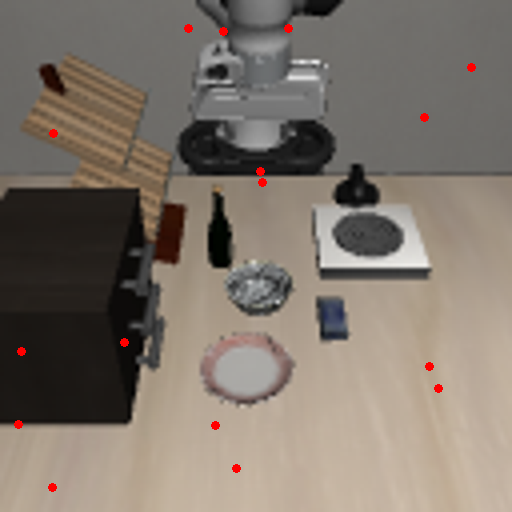

eye_in_hand_rgb


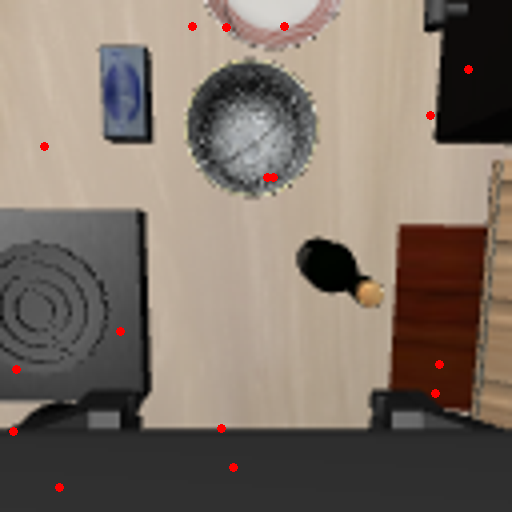

In [6]:
from PIL import Image, ImageDraw
from IPython.display import display
from torch.utils.data import DataLoader
model, saved, device = load_policy(grids_run / "best_model.pt")
dataset = Demonstrations(project_dir, manifest, normalization, saved["config"]["vocab"], "train")
batch = next(iter(DataLoader(dataset, batch_size=1)))
images = {k:v.to(device) for k,v in batch["images"].items()}
with torch.no_grad():
    _, coordinates = model(images, batch["text"].to(device), return_coordinates=True)
for camera in images:
    pixels = (batch["images"][camera][0].permute(1,2,0).numpy()*255).astype("uint8")
    picture = Image.fromarray(pixels).resize((512,512))
    draw = ImageDraw.Draw(picture)
    for x,y in coordinates[camera][0].cpu().tolist():
        x,y = (x+1)*256-0.5, (y+1)*256-0.5
        draw.ellipse((x-4,y-4,x+4,y+4), fill="red")
    print(camera)
    display(picture.transpose(Image.Transpose.FLIP_TOP_BOTTOM))

## 5. Train the second seed
Same budgets and split, different model initialization. Coordinate differences across seeds are expected.

In [7]:
grids_seed1_run = train(project_dir, "grids", seed=1, epochs=10)
uniform_seed1_run = train(project_dir, "uniform", seed=1, epochs=10)

Run: /home/njmcmil/t2-project/runs/grids_seed1_20261117T212424_721238Z
Epoch 1/10: train=0.97421, validation=1.00338
Epoch 2/10: train=0.90648, validation=0.79010
Epoch 3/10: train=0.74200, validation=0.74563
Epoch 4/10: train=0.69275, validation=0.68950
Epoch 5/10: train=0.65109, validation=0.67909
Epoch 6/10: train=0.58555, validation=0.58675
Epoch 7/10: train=0.53482, validation=0.56488
Epoch 8/10: train=0.50244, validation=0.54465
Epoch 9/10: train=0.48001, validation=0.52268
Epoch 10/10: train=0.45936, validation=0.50407
Run: /home/njmcmil/t2-project/runs/uniform_seed1_20261117T212534_924986Z
Epoch 1/10: train=0.97422, validation=1.00328
Epoch 2/10: train=0.97144, validation=0.93301
Epoch 3/10: train=0.87117, validation=0.90063
Epoch 4/10: train=0.83362, validation=0.83801
Epoch 5/10: train=0.73406, validation=0.74109
Epoch 6/10: train=0.68227, validation=0.75033
Epoch 7/10: train=0.65974, validation=0.69736
Epoch 8/10: train=0.63377, validation=0.68845
Epoch 9/10: train=0.61278, 